# M1 RGCs: one mosaic, a wide spectrum of sizes

Supplementary figure for M1, framed as an open question: the 30 manually curated M1 cells form a
mosaic, but their dendritic field sizes span an unusually wide range. We show the full spectrum and the
features that co-vary with size, and leave open whether M1 deserves a split.

- **Mosaic regularity** (as for the A17s): NNRI and VDRI of the hull centroids inside a quality window,
  compared with random labelling of all RGC hull centroids in the same window (99 random fields).
  Cells closer to the window border than to their nearest neighbour (NNRI) or with a Voronoi domain not
  entirely inside it (VDRI) are excluded (Keeley et al. 2020).
- **Clipped cells**: spatial-only border cells of the RGC type finalization (morphological-clustering
  `rgc_final/report14.py`, tier `border`), plus any cell whose dendritic hull comes within `CLIP_MARGIN`
  of the volume's xy edge. Their field size is underestimated, so they are drawn dashed / open, left out
  of the size statistics and never used as examples.

The M1 cells are not all in the figure dataframe (2026-09-16), so all per-cell features are computed here
from the skeletons in `swc-m1/` with minimal copies of the eyewire2-datajoint definitions
(`utils/m1_features.py`): dendritic convex hull (`convex_hull.py`), dendrite length / hull area, waviness
`excess_mean` (`dendrite_waviness.py`), and soma radius from the skeleton's soma (smaller than the
dataframe's mesh-based `soma_rad_um` by ~1 um, but measured the same way for all 30 cells).

# Imports

In [1]:
import os
import sys

import matplotlib
import numpy as np
import pandas as pd
import skeliner as sk
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon as MplPolygon, Rectangle
from scipy import stats

import cell_mosaics as cm

In [2]:
sys.path.append("../utils")

import data_io
from m1_features import cell_features
from plot_cells import plot_cell_morphologies
from style import set_rc_params

In [3]:
set_rc_params()

# Data

In [4]:
config = data_io.get_data_config()
version = config.get("version", None)
file_path = data_io.get_file_path(config)
m1_skel_dir = os.path.join(config['root'], 'swc-m1')

assert os.path.isfile(file_path), file_path
assert os.path.isdir(m1_skel_dir), m1_skel_dir

In [5]:
fig_dir = f'../figures/RGC/v{version}'
os.makedirs(fig_dir, exist_ok=True)

# Parameters

In [6]:
M1_IDS = [
    720575940548266425, 720575940548339331, 720575940551271136, 720575940555453298, 720575940556170858,
    720575940557079811, 720575940559177956, 720575940561454270, 720575940561487123, 720575940562345102,
    720575940562833781, 720575940562912463, 720575940563797232, 720575940564572573, 720575940565124260,
    720575940566002793, 720575940566034818, 720575940567431585, 720575940568135130, 720575940569236062,
    720575940569432260, 720575940570283432, 720575940570468690, 720575940570688555, 720575940573077148,
    720575940573946656, 720575940574685257, 720575940578969034, 720575940581530120, 720575940582220414,
]
# Spatial-only border cells (tier 'border') of RGC type finalization round 14 (morphological-clustering
# rgc_final/report14.py, cache rgc_final_round14.pkl).
BORDER_TIER = [
    720575940548266425, 720575940555453298, 720575940567431585, 720575940569432260, 720575940582220414,
]

SIZE_CMAP = 'viridis'
INK, MUTED, FAINT = '#2b2b2a', '#77776f', '#c4c3bf'
RANDOM_FILL, RANDOM_INK = '#c4c3bf', '#5c5b57'

# Quality window (x_min, x_max, y_min, y_max) in um for the regularity statistics: the RGC window of the
# type finalization (morphological-clustering rgc_final/criteria.yaml).
FIELD = (200, 1000, 300, 1000)
CLIP_MARGIN = 20.0  # um; hull this close to the volume's xy edge = clipped
N_EXAMPLES = 6      # example cells, from the smallest to the largest unclipped cell
N_SIMULATIONS = 99
SEED = 42

# Per-cell features from the skeletons

In [7]:
m1 = pd.DataFrame([
    dict(id=cell_id, **cell_features(sk.io.load_swc(os.path.join(m1_skel_dir, f'{cell_id}.swc'))))
    for cell_id in M1_IDS
]).set_index('id')

# Volume footprint: extent of all somata in the dataframe.
df = pd.read_parquet(file_path, columns=['cellclass_final', 'soma_x_um', 'soma_y_um', 'hull_center_x', 'hull_center_y'])
VOLUME = (df.soma_x_um.min(), df.soma_x_um.max(), df.soma_y_um.min(), df.soma_y_um.max())


def edge_distance(hull_points, bounds=VOLUME):
    return min(hull_points[:, 0].min() - bounds[0], bounds[1] - hull_points[:, 0].max(),
               hull_points[:, 1].min() - bounds[2], bounds[3] - hull_points[:, 1].max())


m1['edge_dist'] = [edge_distance(h) for h in m1.hull_points]
m1['clipped'] = (m1.edge_dist < CLIP_MARGIN) | m1.index.isin(BORDER_TIER)
print(f"{len(m1)} M1 cells, {m1.clipped.sum()} clipped ({np.sum(m1.edge_dist < CLIP_MARGIN)} at the volume edge, "
      f"{np.isin(BORDER_TIER, m1.index).sum()} border tier)")
m1.drop(columns='hull_points').round(2)

30 M1 cells, 13 clipped (10 at the volume edge, 5 border tier)


,soma_x_um,soma_y_um,soma_z_um,soma_rad_um,hull_center_x,hull_center_y,hull_area,hull_diameter,dendrite_length,dendrite_density,waviness,edge_dist,clipped
id,,,,,,,,,,,,,
720575940548266425,308.12,1020.75,-13.23,4.60,271.41,951.63,17755.11,150.35,1257.21,70.81,0.06,92.44,True
720575940548339331,981.54,422.98,-14.14,5.22,963.30,462.64,27002.78,185.42,711.36,26.34,0.03,14.01,True
720575940551271136,245.77,570.61,-14.59,4.36,211.55,612.64,38891.55,222.53,1134.37,29.17,0.04,39.70,False
720575940555453298,755.34,382.04,-14.39,4.93,684.32,394.95,19893.69,159.15,908.17,45.65,0.04,249.66,True
720575940556170858,605.05,529.24,-17.00,4.59,605.56,500.07,69245.82,296.93,2122.02,30.64,0.06,258.43,False
720575940557079811,350.59,596.63,-14.06,4.30,329.01,622.84,31926.69,201.62,1468.12,45.98,0.05,129.96,False
720575940559177956,483.36,420.67,-15.21,4.80,419.58,442.50,76113.47,311.30,2282.82,29.99,0.04,205.58,False
720575940561454270,717.88,977.40,-14.68,4.99,704.29,943.52,69562.73,297.61,2522.42,36.26,0.05,4.39,True
720575940561487123,990.62,661.31,-13.07,4.10,984.17,648.97,53466.42,260.91,2122.83,39.70,0.05,13.94,True


# Mosaic regularity vs. random labelling of RGCs

In [8]:
STATISTICS = ('nnd_regularity_index', 'voronoi_regularity_index')


def in_bounds(positions, bounds):
    return ((positions[:, 0] >= bounds[0]) & (positions[:, 0] <= bounds[1])
            & (positions[:, 1] >= bounds[2]) & (positions[:, 1] <= bounds[3]))


def spacing(n_cells, field=FIELD):
    return np.sqrt((field[1] - field[0]) * (field[3] - field[2]) / n_cells)


def compare_to_random_labelling(positions, pool_positions, field=FIELD, n_simulations=N_SIMULATIONS,
                                drp_kwargs=None, seed=None):
    """Rank a real mosaic's NNRI / VDRI among random same-size subsets of the pool (as for the A17s)."""
    rng = np.random.default_rng(seed)
    observed = cm.regularity_statistics(positions, field, drp_kwargs)
    simulated = {stat: np.empty(n_simulations) for stat in STATISTICS}
    simulations = []
    for s in range(n_simulations):
        sim_positions = pool_positions[rng.choice(len(pool_positions), len(positions), replace=False)]
        stats_s = cm.regularity_statistics(sim_positions, field, drp_kwargs)
        for stat in STATISTICS:
            simulated[stat][s] = stats_s[stat]
        simulations.append(sim_positions)
    result = {'observed': observed, 'simulations': simulations}
    for stat in STATISTICS:
        valid = simulated[stat][~np.isnan(simulated[stat])]
        result[stat] = {
            'observed': observed[stat], 'simulated': simulated[stat], 'ratio': observed[stat] / valid.mean(),
            'p_greater': (1 + np.sum(valid >= observed[stat])) / (len(valid) + 1),
        }
    return result


positions = m1[['hull_center_x', 'hull_center_y']].to_numpy()
in_field = in_bounds(positions, FIELD)
pool_positions = df.loc[df.cellclass_final == 'RGC', ['hull_center_x', 'hull_center_y']].dropna().to_numpy()
pool_positions = pool_positions[in_bounds(pool_positions, FIELD)]
res = compare_to_random_labelling(positions[in_field], pool_positions, seed=SEED,
                                  drp_kwargs={'n_bins': 20, 'max_radius': 2.5 * spacing(in_field.sum())})
print(f"{in_field.sum()} M1 cells in the window, pool {len(pool_positions)} RGCs")
for stat in STATISTICS:
    r = res[stat]
    print(f"{stat}: real {r['observed']:.2f}, random {np.nanmean(r['simulated']):.2f}, "
          f"ratio {r['ratio']:.2f}, p {r['p_greater']:.3f}")

29 M1 cells in the window, pool 2667 RGCs
nnd_regularity_index: real 1.23, random 2.09, ratio 0.59, p 0.970
voronoi_regularity_index: real 2.43, random 2.21, ratio 1.10, p 0.310


# Size spectrum and correlated features

In [9]:
full = m1[~m1.clipped].sort_values('hull_diameter')
# Examples: unclipped cells closest to evenly spaced quantiles of the field size.
targets = np.quantile(full.hull_diameter, np.linspace(0, 1, N_EXAMPLES))
examples = []
for t in targets:
    candidates = full.drop(index=examples)
    examples.append((candidates.hull_diameter - t).abs().idxmin())
examples = sorted(examples, key=lambda c: m1.hull_diameter[c])
print('examples:', [(c, round(m1.hull_diameter[c])) for c in examples])

FEATURES = [
    ('soma_rad_um', 'Soma radius (µm)'),
    ('dendrite_density', 'Dendrite density\n(µm / 1000 µm²)'),
    ('waviness', 'Waviness\n(excess path length)'),
]
correlations = {col: stats.spearmanr(full.hull_diameter, full[col]) for col, _ in FEATURES}
for col, r in correlations.items():
    print(f"{col}: Spearman rho {r.statistic:.2f}, p {r.pvalue:.3g} (n = {len(full)} unclipped)")

examples: [(np.int64(720575940573946656), 159), (np.int64(720575940578969034), 199), (np.int64(720575940569236062), 206), (np.int64(720575940551271136), 223), (np.int64(720575940566034818), 284), (np.int64(720575940559177956), 311)]
soma_rad_um: Spearman rho 0.42, p 0.0919 (n = 17 unclipped)
dendrite_density: Spearman rho -0.49, p 0.0445 (n = 17 unclipped)
waviness: Spearman rho -0.00, p 0.985 (n = 17 unclipped)


# Figure

In [10]:
size_norm = matplotlib.colors.Normalize(full.hull_diameter.min(), full.hull_diameter.max())
size_cmap = plt.get_cmap(SIZE_CMAP)


def draw_hulls(ax, cells, color_of, bounds, show_field=True, alpha=0.18):
    """Dendritic hulls (clipped cells dashed) with their centroids; window dotted."""
    for c in cells:
        h = m1.hull_points[c]
        col = color_of(c)
        ls = '--' if m1.clipped[c] else '-'
        ax.add_patch(MplPolygon(h, closed=True, fc=col, alpha=alpha, ec='none'))
        ax.add_patch(MplPolygon(h, closed=True, fill=False, ec=col, lw=0.7, ls=ls))
        ax.plot(m1.hull_center_x[c], m1.hull_center_y[c], 'o', ms=2.2, color=col, mec='white', mew=0.3)
    if show_field:
        ax.add_patch(Rectangle((FIELD[0], FIELD[2]), FIELD[1] - FIELD[0], FIELD[3] - FIELD[2],
                               fill=False, ec=MUTED, lw=0.6, ls=':'))
    ax.add_patch(Rectangle((VOLUME[0], VOLUME[2]), VOLUME[1] - VOLUME[0], VOLUME[3] - VOLUME[2],
                           fill=False, ec=FAINT, lw=0.6))
    ax.set(xlim=bounds[:2], ylim=bounds[2:], xticks=[], yticks=[])
    ax.set_aspect('equal')
    for spine in ax.spines.values():
        spine.set_visible(False)


def draw_voronoi(ax, positions, color=MUTED):
    """Voronoi domains the VDRI keeps (inside the window)."""
    keep = cm.voronoi_border_mask(positions, FIELD)
    polygons, _, index = cm.voronoi_domain_polygons(positions)
    segments = [np.vstack([p, p[:1]]) for p, j in zip(polygons, index) if keep[j]]
    ax.add_collection(LineCollection(segments, colors=color, linewidths=0.4, alpha=0.8))


def draw_index_bars(ax, stat_res, color, ylabel):
    sims = stat_res['simulated'][~np.isnan(stat_res['simulated'])]
    ax.bar(0, stat_res['observed'], width=0.6, color=color)
    ax.bar(1, sims.mean(), width=0.6, color=RANDOM_FILL, yerr=sims.std(), capsize=2,
           error_kw={'elinewidth': 0.7, 'capthick': 0.7, 'ecolor': RANDOM_INK})
    rng = np.random.default_rng(0)
    ax.scatter(1 + rng.uniform(-0.17, 0.17, len(sims)), sims, s=2, color=RANDOM_INK, linewidths=0, alpha=0.6, zorder=3)
    ax.set_xticks([0, 1], ['M1', 'random'], rotation=90)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel(ylabel, labelpad=1)
    p = stat_res['p_greater']
    ax.set_title(f"ratio {stat_res['ratio']:.2f}\np = {p:.2f}" if p >= 0.01 else f"ratio {stat_res['ratio']:.2f}\np = {p:.3f}",
                 fontsize=7, pad=2)


def scatter_cells(ax, x, y):
    """Unclipped cells filled, coloured by field size; clipped cells open."""
    full_ = m1[~m1.clipped]
    ax.scatter(full_[x], full_[y], s=12, c=size_cmap(size_norm(full_.hull_diameter)), edgecolor=INK, lw=0.3, zorder=3)
    ax.scatter(m1.loc[m1.clipped, x], m1.loc[m1.clipped, y], s=12, facecolor='white', edgecolor=MUTED, lw=0.8, zorder=3)


def scale_bar(ax, bounds, size=200, pad=20):
    x1, y0 = bounds[1] - 10, bounds[2] + pad
    ax.plot([x1 - size, x1], [y0, y0], color=INK, lw=1.2, solid_capstyle='butt')
    ax.text(x1 - size / 2, y0 + 8, f'{size} µm', ha='center', va='bottom', fontsize=6)

[Info] scikit-sparse not found. Falling back to scipy.sparse.linalg.spsolve.


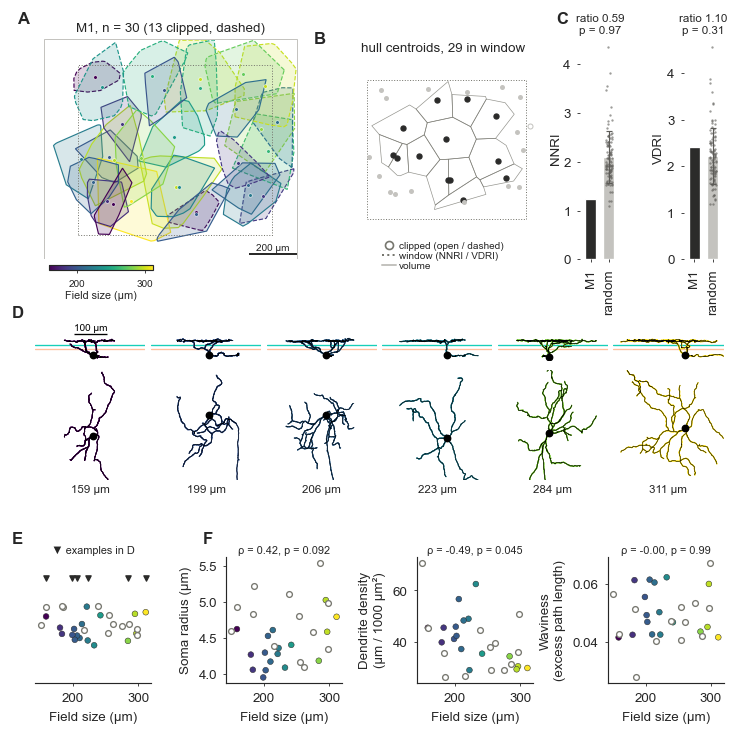

In [11]:
MAP = (VOLUME[0] - 10, VOLUME[1] + 10, 200, VOLUME[3] + 10)  # no M1 cells below y ~ 275 um

fig = plt.figure(figsize=(7.4, 7.0))
outer = fig.add_gridspec(3, 1, height_ratios=(1.5, 1.05, 0.85), hspace=0.42)

# Row A: full mosaic (hulls coloured by field size) | Voronoi of the window | NNRI / VDRI
grid_a = outer[0].subgridspec(1, 3, width_ratios=(1.6, 1.25, 0.85), wspace=0.15)
ax_mosaic = fig.add_subplot(grid_a[0])
ax_vor = fig.add_subplot(grid_a[1])
axs_bars = grid_a[2].subgridspec(1, 2, wspace=1.6).subplots()

draw_hulls(ax_mosaic, m1.index, lambda c: size_cmap(size_norm(m1.hull_diameter[c])), MAP)
ax_mosaic.set_title(f'M1, n = {len(m1)} ({m1.clipped.sum()} clipped, dashed)', fontsize=8, pad=3)
scale_bar(ax_mosaic, MAP)
sm = matplotlib.cm.ScalarMappable(norm=size_norm, cmap=size_cmap)
ax_cbar = ax_mosaic.inset_axes([0.03, -0.05, 0.4, 0.025])
cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label('Field size (µm)', fontsize=6.5, labelpad=1)
ax_cbar.tick_params(labelsize=6)

draw_voronoi(ax_vor, positions[in_field])
keep = cm.voronoi_border_mask(positions[in_field], FIELD)
# Centroids kept for the VDRI (filled), excluded at the window border (faded), outside the window (open).
ax_vor.scatter(*positions[in_field][keep].T, s=9, color=INK, zorder=3)
ax_vor.scatter(*positions[in_field][~keep].T, s=9, color=FAINT, lw=0, zorder=3)
ax_vor.scatter(*positions[~in_field].T, s=9, facecolor='white', edgecolor=FAINT, lw=0.6, zorder=3)
ax_vor.add_patch(Rectangle((FIELD[0], FIELD[2]), FIELD[1] - FIELD[0], FIELD[3] - FIELD[2],
                           fill=False, ec=MUTED, lw=0.6, ls=':'))
ax_vor.set(xlim=MAP[:2], ylim=MAP[2:], xticks=[], yticks=[])
ax_vor.set_aspect('equal')
for spine in ax_vor.spines.values():
    spine.set_visible(False)
ax_vor.set_title(f'hull centroids, {in_field.sum()} in window', fontsize=8, pad=3)

draw_index_bars(axs_bars[0], res['nnd_regularity_index'], INK, 'NNRI')
draw_index_bars(axs_bars[1], res['voronoi_regularity_index'], INK, 'VDRI')

# Row B: example cells across the size range, coloured by field size
axs_ex = outer[1].subgridspec(2, N_EXAMPLES, height_ratios=(1.0, 4), wspace=0.05, hspace=0.05).subplots()
rad_skel = 170
plot_cell_morphologies(
    m1.loc[examples], rad=rad_skel, skel_dir=m1_skel_dir,
    color_list=[size_cmap(size_norm(m1.hull_diameter[c])) for c in examples], size=100, show_on_tsne=False,
    fig=fig, axs=axs_ex, sb_fontsize=6, zlim=(-30, 50))
for ax in axs_ex.flat:
    ax.set(xlabel='', ylabel='', xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)
for ax, c in zip(axs_ex[1], examples):
    ax.text(0.5, -0.04, f'{m1.hull_diameter[c]:.0f} µm', transform=ax.transAxes, ha='center', va='top',
            fontsize=7)

# Row C: size distribution | feature vs size (x3)
grid_c = outer[2].subgridspec(1, 4, wspace=0.65)
ax_size = fig.add_subplot(grid_c[0])
axs_feat = [fig.add_subplot(grid_c[k]) for k in range(1, 4)]

rng = np.random.default_rng(1)
m1['jitter'] = rng.uniform(-0.18, 0.18, len(m1))
scatter_cells(ax_size, 'hull_diameter', 'jitter')
ax_size.scatter([m1.hull_diameter[c] for c in examples], np.full(len(examples), 0.42), marker='v', s=10, color=INK)
ax_size.set(ylim=(-0.5, 0.6), yticks=[], xlabel='Field size (µm)')
ax_size.spines['left'].set_visible(False)
ax_size.set_title('▼ examples in D', fontsize=6.5, pad=2)

for ax, (col, label) in zip(axs_feat, FEATURES):
    scatter_cells(ax, 'hull_diameter', col)
    r = correlations[col]
    ax.set(xlabel='Field size (µm)', ylabel=label)
    ax.set_title(f'ρ = {r.statistic:.2f}, p = {r.pvalue:.2g}', fontsize=6.5, pad=2)

handles = [Line2D([], [], ls='', marker='o', mfc='white', mec=MUTED, label='clipped (open / dashed)'),
           Line2D([], [], color=MUTED, ls=':', label='window (NNRI / VDRI)'),
           Line2D([], [], color=FAINT, label='volume')]
ax_vor.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=6,
              handlelength=1.4, ncol=1)

for label, ax in [('A', ax_mosaic), ('B', ax_vor), ('C', axs_bars[0]), ('D', axs_ex[0, 0]), ('E', ax_size),
                  ('F', axs_feat[0])]:
    ax.annotate(label, xy=(0, 1), xycoords='axes fraction', xytext=(-14, 6), textcoords='offset points',
                fontsize=10, fontweight='bold', ha='left', va='bottom')

fig.savefig(f'{fig_dir}/M1_mosaic_spectrum.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/M1_mosaic_spectrum.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
from watermark import watermark
print(watermark())

Last updated: 2026-11-13T14:44:49.913594+01:00

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.13.0

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
CPU cores   : 8
Architecture: 64bit

